In [8]:
from utils import get_hdf5_files, get_filename, get_continuous_behaviors, get_discrete_states, get_eigenworms, get_kymograph, get_neuronal_traces, get_variance_explained

import os
import math
from matplotlib import pyplot as plt
from matplotlib import colors, patches
import numpy as np
import pandas as pd
import seaborn as sns

from sklearn.decomposition import PCA
from sklearn.cross_decomposition import CCA

In [2]:
path = f'{os.getcwd()}/../data/{os.path.basename(os.getcwd())}/exported_data_/'
hdf5files = get_hdf5_files(path)
filenames = [get_filename(file) for file in hdf5files]
continuous_behaviors = [get_continuous_behaviors(file) for file in hdf5files]
discrete_states = [get_discrete_states(file) for file in hdf5files]
eigenworms = [get_eigenworms(file) for file in hdf5files]
kymographs = [get_kymograph(file) for file in hdf5files]
traces = [get_neuronal_traces(file) for file in hdf5files]

In [3]:
for i in range(len(filenames)):
	mask = eigenworms[i].notna().all(axis=1)
	#continuous_behaviors[i] = continuous_behaviors[i][mask]
	discrete_states[i] = discrete_states[i][mask]
	eigenworms[i] = eigenworms[i][mask]
	traces[i] = traces[i][mask]

	#kymographs[i] = kymographs[i][mask]
	#filenames[i] = filenames[i][mask]

0.42925548728814567 0.6894092115431191


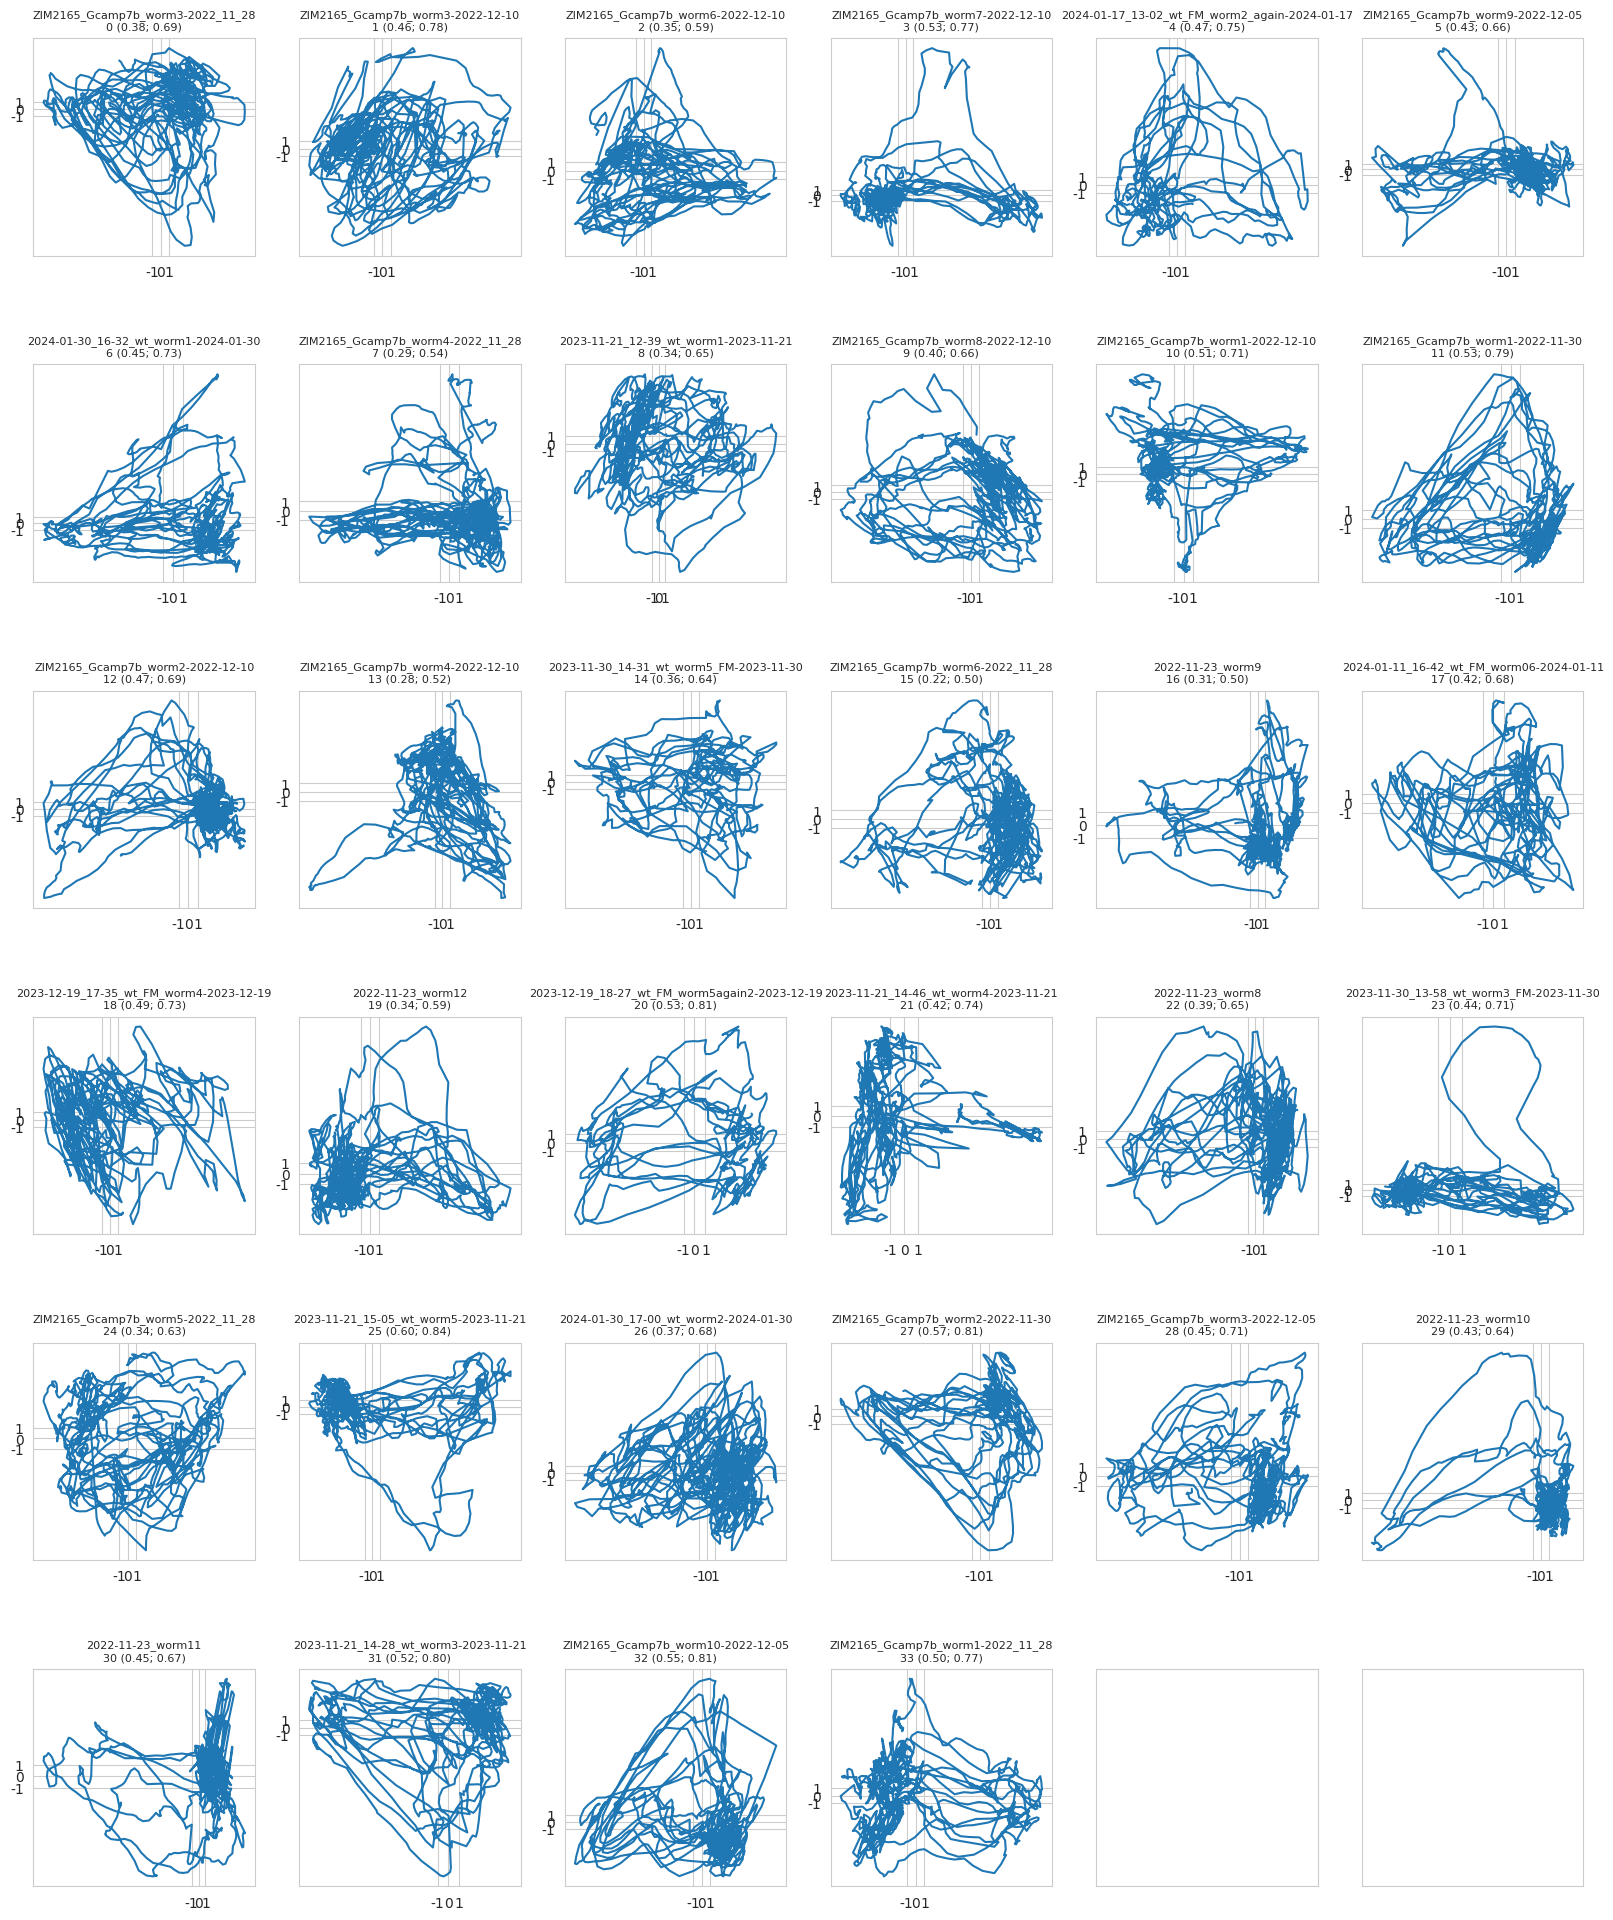

In [4]:
selection = ['REV', 'VENTRAL_TURN', 'DORSAL_TURN', 'PAUSE']

modes_manifold = list()
traces_manifold = list()
cca_man_loadings = list()
man_vars_expl_rs = list()  # variance explained with respect to the reconstructed PCA data
man_vars_expl = list()
for trace, ds in zip(traces, discrete_states):

	pca = PCA(n_components=5)
	trace_reduced_pca = pca.fit_transform(trace.values)
	trace_reconstructed_pca = pca.inverse_transform(trace_reduced_pca)

	cca = CCA(n_components=2, scale=True)
	trace_reduced_cca, ds_reduced_cca = cca.fit_transform(trace_reconstructed_pca, ds[selection].values)
	trace_reconstructed_cca, ds_reconstructed_cca = cca.inverse_transform(trace_reduced_cca, ds_reduced_cca)

	modes_manifold.append(pd.DataFrame(data=trace_reduced_cca, columns=[f'CC{n+1}' for n in range(2)]))
	traces_manifold.append(pd.DataFrame(data=trace_reconstructed_cca, columns=trace.columns))

	cca_man_loadings.append((cca.x_loadings_, cca.y_loadings_))

	X_var_ratio_rs = get_variance_explained(trace_reconstructed_pca, trace_reconstructed_cca)
	X_var_ratio = get_variance_explained(trace, trace_reconstructed_cca)
	man_vars_expl_rs.append(X_var_ratio_rs)
	man_vars_expl.append(X_var_ratio)


n_plots = 36
dim = math.ceil(math.sqrt(n_plots))
fig, axes = plt.subplots(dim, dim, figsize=(20, 24))
for i in range(n_plots):
	axes[i // dim, i % dim].set_xticklabels([])
	axes[i // dim, i % dim].set_yticklabels([])
	axes[i // dim, i % dim].grid(False)

scale = [-1, 0, 1]
for i, mode in enumerate(modes_manifold):
	axes[i // dim, i % dim].plot(mode['CC1'], mode['CC2'])
	axes[i // dim, i % dim].set_xticks(scale)
	axes[i // dim, i % dim].set_xticklabels(scale)
	axes[i // dim, i % dim].set_yticks(scale)
	axes[i // dim, i % dim].set_yticklabels(scale)
	axes[i // dim, i % dim].grid(True)
	axes[i // dim, i % dim].set_title(f'{filenames[i][:-14]}\n{i} ({man_vars_expl[i]:.2f}; {man_vars_expl_rs[i]:.2f})', fontsize=8)

plt.subplots_adjust(hspace=0.5)
print(np.mean(np.array(man_vars_expl)), np.mean(np.array(man_vars_expl_rs)))

In [5]:
traces_residual = [pd.DataFrame(data=trace.values - trace_manifold.values, columns=trace.columns) for trace, trace_manifold in zip(traces, traces_manifold)]

In [23]:
modes_concrete = list()
traces_concrete = list()
cca_con_loadings = list()
con_vars_expl_rs = list()  # variance explained with respect to the manifold-residual data
con_vars_expl = list()
for trace, trace_residual, ew in zip(traces, traces_residual, eigenworms):
	cca = CCA(n_components=5, scale=True)

	trace_residual_reduced, ew_reduced = cca.fit_transform(trace_residual.values, ew.values)
	trace_residual_reconstructed, ew_reconstructed = cca.inverse_transform(trace_residual_reduced, ew_reduced)

	modes_concrete.append(pd.DataFrame(data=trace_residual_reduced, columns=[f'CC{i + 1}' for i in range(5)]))
	traces_concrete.append(pd.DataFrame(data=trace_residual_reconstructed, columns=trace_residual.columns))

	cca_con_loadings.append((cca.x_loadings_, cca.y_loadings_))

	X_var_ratio_rs = get_variance_explained(trace_residual, trace_residual_reconstructed)
	X_var_ratio = get_variance_explained(trace, trace_residual_reconstructed)
	con_vars_expl_rs.append(X_var_ratio_rs)
	con_vars_expl.append(X_var_ratio)


n_plots = 36
dim = math.ceil(math.sqrt(n_plots))
fig, axes = plt.subplots(dim, dim, figsize=(20, 24))
for i in range(n_plots):
	axes[i // dim, i % dim].set_xticklabels([])
	axes[i // dim, i % dim].set_yticklabels([])
	axes[i // dim, i % dim].grid(False)

scale = [-1, 0, 1]
for i, mode in enumerate(modes_concrete):
	axes[i // dim, i % dim].plot(mode['CC1'], mode['CC2'])
	axes[i // dim, i % dim].set_xticks(scale)
	axes[i // dim, i % dim].set_xticklabels(scale)
	axes[i // dim, i % dim].set_yticks(scale)
	axes[i // dim, i % dim].set_yticklabels(scale)
	axes[i // dim, i % dim].grid(True)
	axes[i // dim, i % dim].set_title(f'{filenames[i][:-14]}\n{i} ({con_vars_expl[i]:.2f}; {con_vars_expl_rs[i]:.2f})', fontsize=8)

plt.subplots_adjust(hspace=0.5)
print(np.mean(np.array(con_vars_expl)), np.mean(np.array(con_vars_expl_rs)))

In [ ]:
traces_other = [pd.DataFrame(data=trace_residual.values-trace_concrete.values, columns=trace_residual.columns) for trace_residual, trace_concrete in zip(traces_residual, traces_concrete)]

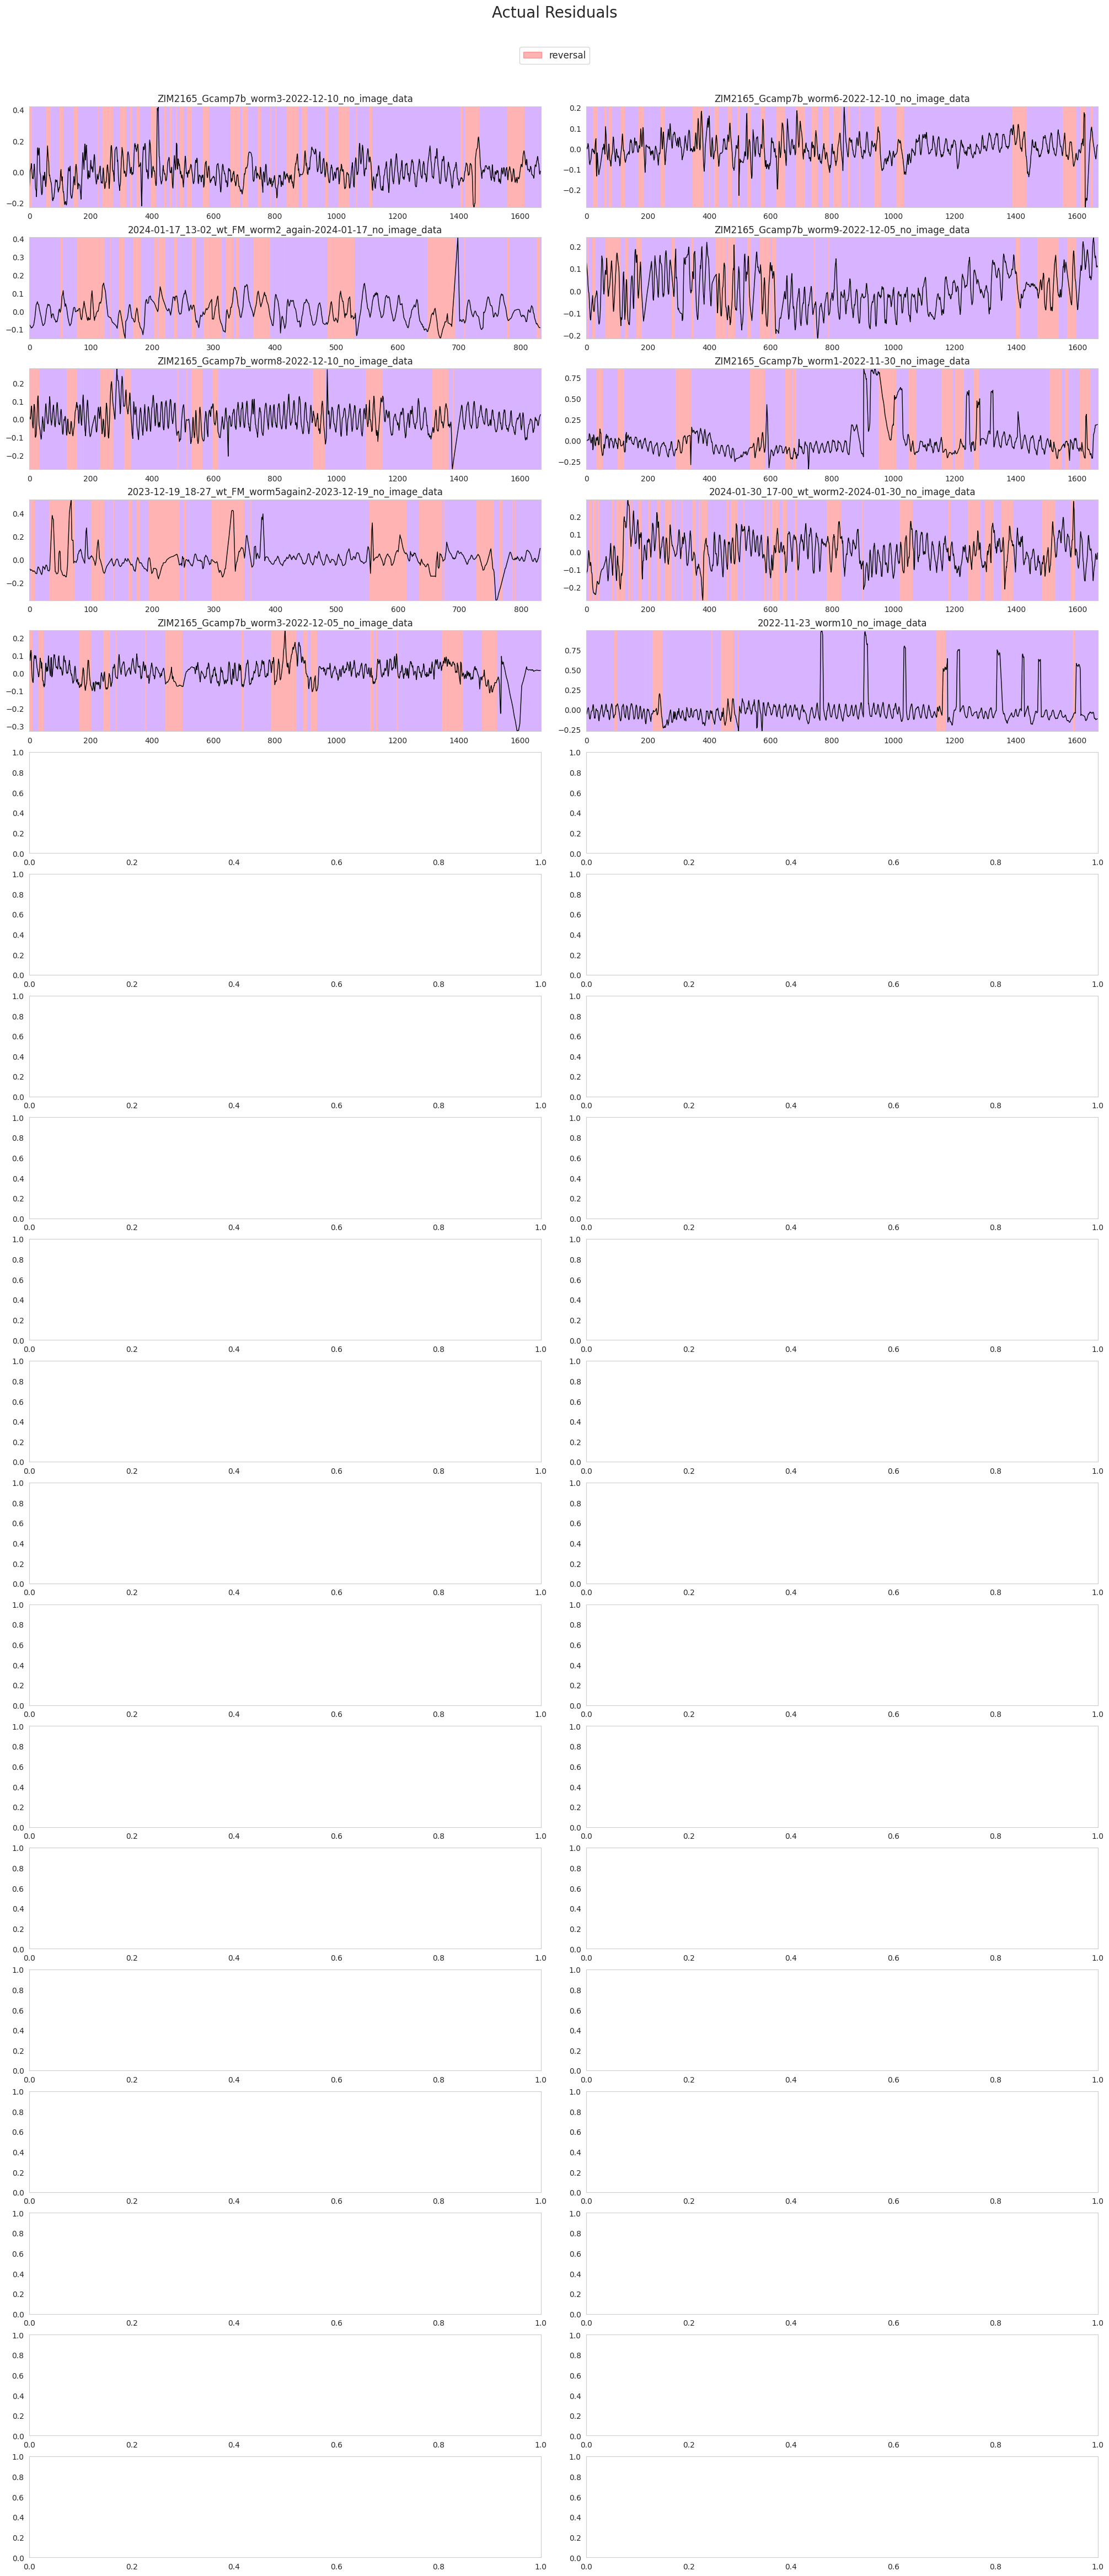

In [9]:
dim1, dim2 = 20, 2
fig, axes = plt.subplots(dim1, dim2, figsize=(20, 45), constrained_layout=True)
for i in range(dim1 * dim2):
	#axes[i // dim2, i % dim2].set_xticklabels([])
	#axes[i // dim2, i % dim2].set_yticklabels([])
	axes[i // dim2, i % dim2].grid(False)

neuron = 'DD01'
i = 0
for filename, traces, states in zip(filenames, traces_residual, discrete_states):
	if neuron in traces:
		trace = traces[neuron]
		heatmap = states['REV'].values.reshape(-1, 1) * 0.1

		min_val, max_val = min(trace), max(trace)
		axes[i // dim2, i % dim2].imshow(
			heatmap.T, aspect='auto', cmap='rainbow', interpolation='nearest', alpha=0.3, extent=[0, heatmap.shape[0], min_val, max_val]
		)
		axes[i // dim2, i % dim2].plot(trace, color='black', linewidth=1.0)
		axes[i // dim2, i % dim2].grid(False)
		axes[i // dim2, i % dim2].set_title(f'{filename}', fontsize=12)
		i += 1

fig.text(0.5, 1.03, f'Actual residual traces of {neuron}', ha='center', fontsize=20)
fig.legend(
    handles=[patches.Patch(color=plt.get_cmap('rainbow')(1.0), alpha=0.3, label='reversal')],
    loc='upper center',
    bbox_to_anchor=(0.5, 1.02),
    ncol=1,
    fontsize='large'
)

# plt.savefig('out/traces_single_residuals.png', dpi=300)